<a href="https://colab.research.google.com/github/rabiakrann/Ileri-Oruntu-Tanima/blob/main/ileri_oruntu_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

In [33]:
SEED = 42
TAU_VALUES = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]     # |corr| thresholds tried in 6.1
BLUE, ORANGE, GREEN, YELLOW, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cd6"

In [34]:
def split_one_class(X, y, seed=SEED):
    normal, anomaly = X[y == 0], X[y == 1]
    X_train, rest_normal = train_test_split(normal, train_size=0.6, random_state=seed)
    X_rest = np.vstack([rest_normal, anomaly])
    y_rest = np.array([0] * len(rest_normal) + [1] * len(anomaly))
    X_val, X_test, y_val, y_test = train_test_split(
        X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=seed)
    return X_train, X_val, y_val, X_test, y_test

In [35]:
thy = loadmat("/content/drive/MyDrive/Colab Notebooks/thyroidori.mat")
wdbc = load_breast_cancer()

In [36]:
DATASETS = {
    "Thyroid": dict(X=thy["X"], y=thy["y"].ravel().astype(int), names=[f"f{i + 1}" for i in range(6)], k=7),
    "WDBC": dict(X=wdbc.data, y=(wdbc.target == 0).astype(int), names=list(wdbc.feature_names), k=5),
}

In [37]:
for name, ds in DATASETS.items():
    Xtr, Xva, yva, Xte, yte = split_one_class(ds["X"], ds["y"])
    ds["Xtr_raw"] = Xtr.copy()
    mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
    Xtr, Xva, Xte = (Xtr - mu) / sd, (Xva - mu) / sd, (Xte - mu) / sd
    ds.update(Xtr=Xtr, Xva=Xva, yva=yva, Xte=Xte, yte=yte, d=Xtr.shape[1])
    ds["Dva"] = np.stack([(Xva[:, j][:, None] - Xtr[:, j][None, :]) ** 2 for j in range(Xtr.shape[1])])
    print(f"{name:<8} k={ds['k']}  d={ds['d']}  train = {len(Xtr)} normal | "
          f"val = {np.sum(yva == 0)}+{np.sum(yva == 1)} | test = {np.sum(yte == 0)}+{np.sum(yte == 1)}"
          f"  (normal+anomaly)")

Thyroid  k=7  d=6  train = 2207 normal | val = 736+46 | test = 736+47  (normal+anomaly)
WDBC     k=5  d=30  train = 214 normal | val = 71+106 | test = 72+106  (normal+anomaly)


In [38]:
def sq_dist(A, B, feats):
    D = np.zeros((len(A), len(B)))
    for j in feats:
        D += (A[:, j][:, None] - B[:, j][None, :]) ** 2
    return D

In [39]:
def one_class_scores(D, k):
    return np.sqrt(np.partition(D, k - 1, axis=1)[:, :k]).mean(axis=1)

In [40]:
def curve_points(y_true, scores):
    P = int(np.sum(y_true == 1))
    N = len(y_true) - P
    order = np.argsort(-scores)
    s, yy = scores[order], y_true[order]
    tp_list, fp_list, tp, fp = [0], [0], 0, 0
    for i in range(len(s)):
        tp += yy[i] == 1
        fp += yy[i] == 0
        if i == len(s) - 1 or s[i + 1] != s[i]:
            tp_list.append(tp)
            fp_list.append(fp)
    return np.array(tp_list), np.array(fp_list), P, N

In [41]:
def trapezoid(x, y):
    return sum((x[i] - x[i - 1]) * (y[i] + y[i - 1]) / 2 for i in range(1, len(x)))

In [42]:
def roc_auc(y_true, scores):
    tp, fp, P, N = curve_points(y_true, scores)
    return trapezoid(fp / N, tp / P)

In [43]:
def pr_auc(y_true, scores):
    tp, fp, P, N = curve_points(y_true, scores)
    precision = np.ones(len(tp))
    precision[1:] = tp[1:] / (tp[1:] + fp[1:])
    return trapezoid(tp / P, precision)

In [44]:
def f1_from_pred(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return 2 * tp / (2 * tp + fp + fn) if tp else 0.0

In [45]:
def best_f1_threshold(y_true, scores):
    cand = np.unique(scores)
    f1s = [f1_from_pred(y_true, (scores > t).astype(int)) for t in cand]
    return cand[int(np.argmax(f1s))]

In [46]:
def score_from_D(ds, D):
    return pr_auc(ds["yva"], one_class_scores(D, ds["k"]))

In [47]:
def val_score(ds, feats):
    return score_from_D(ds, ds["Dva"][sorted(feats)].sum(axis=0))

In [48]:
def test_results(ds, feats):
    feats = list(feats)
    s_va = one_class_scores(sq_dist(ds["Xva"], ds["Xtr"], feats), ds["k"])
    s_te = one_class_scores(sq_dist(ds["Xte"], ds["Xtr"], feats), ds["k"])
    th = best_f1_threshold(ds["yva"], s_va)
    return {"ROC-AUC": roc_auc(ds["yte"], s_te), "PR-AUC": pr_auc(ds["yte"], s_te),
            "F1": f1_from_pred(ds["yte"], (s_te > th).astype(int))}

In [49]:
def covariance_matrix(X):
    n, d = X.shape
    m = X.mean(axis=0)
    C = np.zeros((d, d))
    for i in range(d):
        for j in range(i, d):
            C[i, j] = np.sum((X[:, i] - m[i]) * (X[:, j] - m[j])) / (n - 1)
            C[j, i] = C[i, j]                    # symmetric
    return C

In [50]:
def correlation_matrix(X):
    n, d = X.shape
    m = X.mean(axis=0)
    R = np.eye(d)
    for i in range(d):
        for j in range(i + 1, d):
            a, b = X[:, i] - m[i], X[:, j] - m[j]
            R[i, j] = np.sum(a * b) / (np.sqrt(np.sum(a ** 2)) * np.sqrt(np.sum(b ** 2)))
            R[j, i] = R[i, j]
    return R

In [51]:
def remove_correlated(R, tau):
    remaining = list(range(len(R)))
    removed = []
    while True:
        sub = np.abs(R[np.ix_(remaining, remaining)])
        np.fill_diagonal(sub, 0)
        i, j = np.unravel_index(np.argmax(sub), sub.shape)
        if sub[i, j] <= tau:
            break
        drop = i if sub[i].mean() >= sub[j].mean() else j
        removed.append((remaining[drop], remaining[j if drop == i else i], sub[i, j]))
        remaining.pop(drop)
    return remaining, removed

In [52]:
print("\n" + "=" * 70)
print("6.1 COVARIANCE AND CORRELATION MATRICES (training data)")
print("=" * 70)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
for name, ds in DATASETS.items():
    ds["C_raw"] = covariance_matrix(ds["Xtr_raw"])     # covariance depends on the scale of the features
    ds["R"] = correlation_matrix(ds["Xtr"])             # correlation does not (same for raw / standardized)
    # note: training data contains normal samples only (one-class setting)
    d = ds["d"]
    iu = np.triu_indices(d, 1)
    absr = np.abs(ds["R"][iu])
    print(f"\n{name}: d = {d}, distinct pairs (d^2 - d)/2 = {len(absr)}, max |corr| = {absr.max():.3f}")
    print("  pairs with |corr| > tau: " + ", ".join(f"{t}: {int(np.sum(absr > t))}" for t in TAU_VALUES))
    if d <= 6:
        print("  covariance matrix (raw features) x 1000:\n", ds["C_raw"] * 1000)
        print("  correlation matrix:\n", ds["R"])
    order = np.argsort(-absr)[:5]
    for o in order:
        i, j = iu[0][o], iu[1][o]
        print(f"  {ds['names'][i][:20]:<20} - {ds['names'][j][:20]:<20} corr = {ds['R'][i, j]:+.3f}")


6.1 COVARIANCE AND CORRELATION MATRICES (training data)

Thyroid: d = 6, distinct pairs (d^2 - d)/2 = 15, max |corr| = 0.732
  pairs with |corr| > tau: 0.7: 1, 0.75: 0, 0.8: 0, 0.85: 0, 0.9: 0, 0.95: 0
  covariance matrix (raw features) x 1000:
 [[41.677 -0.066 -3.264 -0.515 -2.708  0.681]
 [-0.066  0.091 -0.044 -0.103  0.077 -0.088]
 [-3.264 -0.044  4.492  2.388  2.302  0.923]
 [-0.515 -0.103  2.388  5.987  2.955  3.045]
 [-2.708  0.077  2.302  2.955  7.505 -0.953]
 [ 0.681 -0.088  0.923  3.045 -0.953  2.894]]
  correlation matrix:
 [[ 1.    -0.034 -0.239 -0.033 -0.153  0.062]
 [-0.034  1.    -0.069 -0.139  0.093 -0.171]
 [-0.239 -0.069  1.     0.461  0.396  0.256]
 [-0.033 -0.139  0.461  1.     0.441  0.732]
 [-0.153  0.093  0.396  0.441  1.    -0.204]
 [ 0.062 -0.171  0.256  0.732 -0.204  1.   ]]
  f4                   - f6                   corr = +0.732
  f3                   - f4                   corr = +0.461
  f4                   - f5                   corr = +0.441
  f3    

In [53]:
print("\nRemoval of highly correlated features (tau chosen on the validation set):")
for name, ds in DATASETS.items():
    rows = []
    for tau in TAU_VALUES:
        kept, removed = remove_correlated(ds["R"], tau)
        rows.append((tau, kept, removed, val_score(ds, kept)))
    all_val = val_score(ds, range(ds["d"]))
    # best validation score; ties -> fewer remaining features
    best = max(rows, key=lambda r: (round(r[3], 6), -len(r[1])))
    ds["corr_rows"], ds["corr_best"] = rows, best
    print(f"\n{name} (validation PR-AUC, all features = {all_val:.4f})")
    for tau, kept, removed, v in rows:
        print(f"  tau = {tau:.2f}: removed {len(removed):>2}, kept {len(kept):>2}, val PR-AUC = {v:.4f}")
    print(f"  selected tau = {best[0]:.2f}; removed features:")
    for drop, partner, c in best[2]:
        print(f"    {ds['names'][drop]:<24} (|corr| = {c:.3f} with {ds['names'][partner]})")


Removal of highly correlated features (tau chosen on the validation set):

Thyroid (validation PR-AUC, all features = 0.8271)
  tau = 0.70: removed  1, kept  5, val PR-AUC = 0.8315
  tau = 0.75: removed  0, kept  6, val PR-AUC = 0.8271
  tau = 0.80: removed  0, kept  6, val PR-AUC = 0.8271
  tau = 0.85: removed  0, kept  6, val PR-AUC = 0.8271
  tau = 0.90: removed  0, kept  6, val PR-AUC = 0.8271
  tau = 0.95: removed  0, kept  6, val PR-AUC = 0.8271
  selected tau = 0.70; removed features:
    f4                       (|corr| = 0.732 with f6)

WDBC (validation PR-AUC, all features = 0.9749)
  tau = 0.70: removed 18, kept 12, val PR-AUC = 0.9807
  tau = 0.75: removed 16, kept 14, val PR-AUC = 0.9804
  tau = 0.80: removed 14, kept 16, val PR-AUC = 0.9781
  tau = 0.85: removed  9, kept 21, val PR-AUC = 0.9727
  tau = 0.90: removed  8, kept 22, val PR-AUC = 0.9727
  tau = 0.95: removed  5, kept 25, val PR-AUC = 0.9711
  selected tau = 0.70; removed features:
    mean radius             

In [54]:
def fisher_scores(X, y):
    m = X.mean(axis=0)
    num, den = np.zeros(X.shape[1]), np.zeros(X.shape[1])
    for c in np.unique(y):
        Xc = X[y == c]
        num += len(Xc) * (Xc.mean(axis=0) - m) ** 2
        den += len(Xc) * Xc.var(axis=0)
    den[den == 0] = np.inf
    return num / den

In [55]:
def sfs(ds):
    selected, remaining, path = [], list(range(ds["d"])), []
    while remaining:
        scores = [val_score(ds, selected + [j]) for j in remaining]            # add feature j
        j = remaining[int(np.argmax(scores))]
        selected.append(j)
        remaining.remove(j)
        path.append((list(selected), max(scores)))
    return path

In [56]:
def sbs(ds):
    selected = list(range(ds["d"]))
    path = [(list(selected), val_score(ds, selected))]
    while len(selected) > 1:
        scores = [val_score(ds, [f for f in selected if f != j]) for j in selected]   # remove feature j
        j = selected[int(np.argmax(scores))]
        selected.remove(j)
        path.append((list(selected), max(scores)))
    return path

In [57]:
def best_of_path(path):
    return max(path, key=lambda p: (round(p[1], 6), -len(p[0])))

In [58]:
print("\n" + "=" * 70)
print("6.2 FEATURE SELECTION")
print("=" * 70)
for name, ds in DATASETS.items():
    print(f"\n{name}: number of non-empty feature subsets 2^d - 1 = {2 ** ds['d'] - 1:.4g}")
    # Fisher score needs both classes; the training set has normals only -> computed on the validation set
    F = fisher_scores(ds["Xva"], ds["yva"])
    rank = list(np.argsort(-F))
    ds["fisher_path"] = [(rank[:m], val_score(ds, rank[:m])) for m in range(1, ds["d"] + 1)]
    ds["fisher_rank"] = rank
    print("  Fisher ranking (top 5): " + ", ".join(f"{ds['names'][j]} ({F[j]:.2f})" for j in rank[:5]))
    ds["sfs_path"] = sfs(ds)
    ds["sbs_path"] = sbs(ds)
    if ds["d"] <= 10:                             # exhaustive search is possible only for small d
        subsets = [list(c) for r in range(1, ds["d"] + 1) for c in itertools.combinations(range(ds["d"]), r)]
        ex = [(s, val_score(ds, s)) for s in subsets]
        ds["exhaustive"] = best_of_path(ex)
        ds["exhaustive_all"] = ex
        print(f"  exhaustive search over {len(ex)} subsets done")


6.2 FEATURE SELECTION

Thyroid: number of non-empty feature subsets 2^d - 1 = 63
  Fisher ranking (top 5): f2 (0.72), f6 (0.41), f4 (0.29), f3 (0.09), f5 (0.01)
  exhaustive search over 63 subsets done

WDBC: number of non-empty feature subsets 2^d - 1 = 1.074e+09
  Fisher ranking (top 5): worst concave points (1.30), worst perimeter (1.12), worst radius (1.09), mean concave points (0.99), mean perimeter (0.90)


In [59]:
print("\n" + "=" * 70)
print("RESULTS ON THE TEST SET (all choices made on the validation set)")
print("=" * 70)
for name, ds in DATASETS.items():
    methods = {"No selection (all features)": (list(range(ds["d"])), val_score(ds, range(ds["d"])))}
    tau, kept, removed, v = ds["corr_best"]
    methods[f"6.1 Correlation removal (tau={tau:.2f})"] = (kept, v)
    methods["6.2 Fisher score (filter)"] = best_of_path(ds["fisher_path"])
    methods["6.2 Forward selection (SFS)"] = best_of_path(ds["sfs_path"])
    methods["6.2 Backward elimination (SBS)"] = best_of_path(ds["sbs_path"])
    if "exhaustive" in ds:
        methods["Exhaustive search (reference)"] = ds["exhaustive"]
    ds["methods"] = {}
    print(f"\n{name}  (selection criterion: validation PR-AUC)")
    print(f"  {'method':<38}{'#feat':>6}{'val':>8}   test: ROC-AUC  PR-AUC     F1")
    for mname, (feats, v) in methods.items():
        res = test_results(ds, feats)
        ds["methods"][mname] = (sorted(feats), v, res)
        vals = "  ".join(f"{x:.3f}" for x in res.values())
        print(f"  {mname:<38}{len(feats):>6}{v:>8.3f}   {vals}")
    for mname, (feats, v, res) in ds["methods"].items():
        if 0 < len(feats) < ds["d"] and len(feats) <= 12:
            print(f"    {mname}: " + ", ".join(ds["names"][j] for j in feats))
    if "exhaustive_all" in ds:
        ranked = sorted(ds["exhaustive_all"], key=lambda p: -p[1])
        pos = {mn: 1 + [sorted(s) for s, _ in ranked].index(sorted(f))
               for mn, (f, _, _) in ds["methods"].items()}
        print("    rank of each subset among all " + f"{len(ranked)} subsets (validation): "
              + ", ".join(f"{mn.split('(')[0].strip()}: {p}" for mn, p in pos.items()))


RESULTS ON THE TEST SET (all choices made on the validation set)

Thyroid  (selection criterion: validation PR-AUC)
  method                                 #feat     val   test: ROC-AUC  PR-AUC     F1
  No selection (all features)                6   0.827   0.991  0.857  0.784
  6.1 Correlation removal (tau=0.70)         5   0.831   0.991  0.864  0.772
  6.2 Fisher score (filter)                  2   0.925   0.993  0.873  0.793
  6.2 Forward selection (SFS)                2   0.925   0.993  0.873  0.793
  6.2 Backward elimination (SBS)             2   0.911   0.992  0.871  0.826
  Exhaustive search (reference)              2   0.925   0.993  0.873  0.793
    6.1 Correlation removal (tau=0.70): f1, f2, f3, f5, f6
    6.2 Fisher score (filter): f2, f6
    6.2 Forward selection (SFS): f2, f6
    6.2 Backward elimination (SBS): f2, f4
    Exhaustive search (reference): f2, f6
    rank of each subset among all 63 subsets (validation): No selection: 32, 6.1 Correlation removal: 28, 6.2 Fis

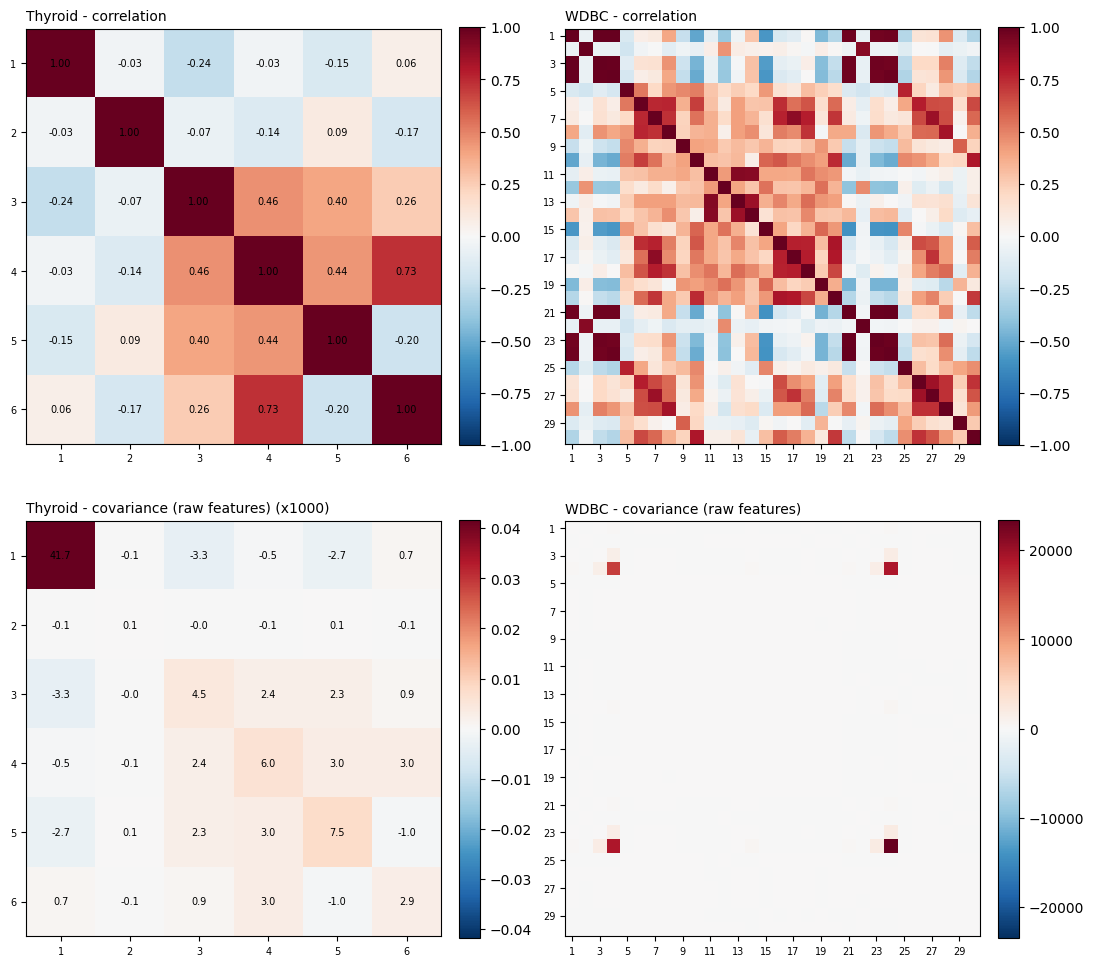

In [60]:
names2 = list(DATASETS)
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for col, name in enumerate(names2):
    ds = DATASETS[name]
    for row, (M, title, cmap) in enumerate([(ds["R"], "correlation", "RdBu_r"),
                                           (ds["C_raw"], "covariance (raw features)", "RdBu_r")]):
        ax = axes[row, col]
        lim = 1 if row == 0 else np.abs(M).max()
        im = ax.imshow(M, cmap=cmap, vmin=-lim, vmax=lim)
        ax.set_title(f"{name} - {title}" + (" (x1000)" if row == 1 and ds["d"] <= 6 else ""),
                     loc="left", fontsize=10)
        ticks = np.arange(ds["d"]) if ds["d"] <= 6 else np.arange(0, ds["d"], 2)
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_xticklabels(ticks + 1, fontsize=7)
        ax.set_yticklabels(ticks + 1, fontsize=7)
        if ds["d"] <= 6:
            for i in range(ds["d"]):
                for j in range(ds["d"]):
                    ax.text(j, i, f"{M[i, j]:.2f}" if row == 0 else f"{M[i, j] * 1000:.1f}",
                            ha="center", va="center", fontsize=7)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig("6_1_corr_cov_matrices.png", dpi=150)

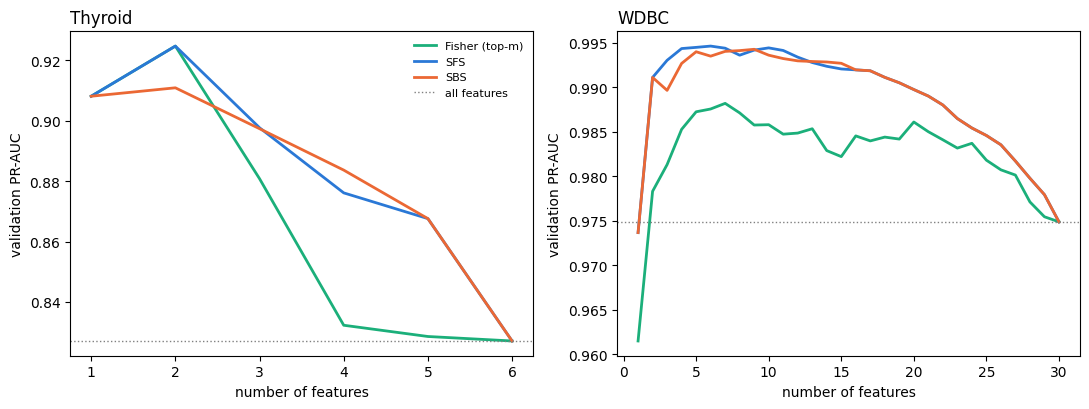

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, names2):
    ds = DATASETS[name]
    for key, label, c in [("fisher_path", "Fisher (top-m)", GREEN), ("sfs_path", "SFS", BLUE),
                          ("sbs_path", "SBS", ORANGE)]:
        pts = sorted((len(f), v) for f, v in ds[key])
        ax.plot([p[0] for p in pts], [p[1] for p in pts], "-", color=c, lw=2, label=label)
    ax.axhline(val_score(ds, range(ds["d"])), color="gray", ls=":", lw=1, label="all features")
    ax.set_title(name, loc="left")
    ax.set_xlabel("number of features")
    ax.set_ylabel("validation PR-AUC")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("6_2_selection_paths.png", dpi=150)


saved figures: 6_1_corr_cov_matrices.png, 6_2_selection_paths.png, 6_2_test_comparison.png


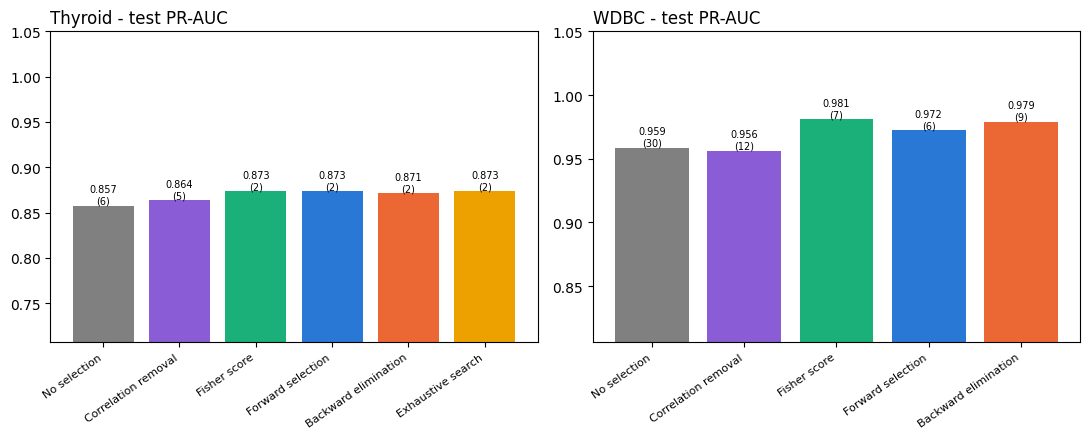

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
colors = ["gray", PURPLE, GREEN, BLUE, ORANGE, YELLOW]
for ax, name in zip(axes, names2):
    ds = DATASETS[name]
    key = "PR-AUC"
    labels = [m.split("(")[0].replace("6.1 ", "").replace("6.2 ", "").strip() for m in ds["methods"]]
    vals = [r[key] for _, _, r in ds["methods"].values()]
    nfeat = [len(f) for f, _, _ in ds["methods"].values()]
    bars = ax.bar(range(len(vals)), vals, color=colors[:len(vals)])
    for b_, v, n in zip(bars, vals, nfeat):
        ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v:.3f}\n({n})", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    lo = min(vals)
    ax.set_ylim(max(0, lo - 0.15), 1.05)
    ax.set_title(f"{name} - test {key}", loc="left")
fig.tight_layout()
fig.savefig("6_2_test_comparison.png", dpi=150)
print("\nsaved figures: 6_1_corr_cov_matrices.png, 6_2_selection_paths.png, 6_2_test_comparison.png")